In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [9]:
#Chargement des données 
df =pd.read_csv("Auto Sales data.csv")

In [10]:
#Exploration rapide
df.head()


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,24/02/2018,828,Shipped,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,NYC,10022,USA,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,07/05/2018,757,Shipped,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,Reims,51100,France,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,01/07/2018,703,Shipped,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,Paris,75508,France,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,25/08/2018,649,Shipped,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,Pasadena,90003,USA,Young,Julie,Medium
4,10168,36,96.66,1,3479.76,28/10/2018,586,Shipped,Motorcycles,95,S10_1678,Technics Stores Inc.,6505556809,9408 Furth Circle,Burlingame,94217,USA,Hirano,Juri,Medium


In [11]:
df.shape


(2747, 20)

In [12]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2747 entries, 0 to 2746
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ORDERNUMBER           2747 non-null   int64  
 1   QUANTITYORDERED       2747 non-null   int64  
 2   PRICEEACH             2747 non-null   float64
 3   ORDERLINENUMBER       2747 non-null   int64  
 4   SALES                 2747 non-null   float64
 5   ORDERDATE             2747 non-null   object 
 6   DAYS_SINCE_LASTORDER  2747 non-null   int64  
 7   STATUS                2747 non-null   object 
 8   PRODUCTLINE           2747 non-null   object 
 9   MSRP                  2747 non-null   int64  
 10  PRODUCTCODE           2747 non-null   object 
 11  CUSTOMERNAME          2747 non-null   object 
 12  PHONE                 2747 non-null   object 
 13  ADDRESSLINE1          2747 non-null   object 
 14  CITY                  2747 non-null   object 
 15  POSTALCODE           

In [13]:
df.describe()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,DAYS_SINCE_LASTORDER,MSRP
count,2747.000000,2747.000000,2747.000000,2747.000000,2747.000000,2747.000000,2747.000000
mean,10259.761558,35.103021,101.098952,6.491081,3553.047583,1757.085912,100.691664
std,91.877521,9.762135,42.042549,4.230544,1838.953901,819.280576,40.114802
min,10100.000000,6.000000,26.880000,1.000000,482.130000,42.000000,33.000000
25%,10181.000000,27.000000,68.745000,3.000000,2204.350000,1077.000000,68.000000
50%,10264.000000,35.000000,95.550000,6.000000,3184.800000,1761.000000,99.000000
75%,10334.500000,43.000000,127.100000,9.000000,4503.095000,2436.500000,124.000000
max,10425.000000,97.000000,252.870000,18.000000,14082.800000,3562.000000,214.000000


In [14]:
#Conversion des dates 
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"])

C:\Users\DC\AppData\Local\Temp\ipykernel_9836\3617952795.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"])


In [15]:
#Valeurs manquantes
df.isnull().sum()

ORDERNUMBER             0
QUANTITYORDERED         0
PRICEEACH               0
ORDERLINENUMBER         0
SALES                   0
ORDERDATE               0
DAYS_SINCE_LASTORDER    0
STATUS                  0
PRODUCTLINE             0
MSRP                    0
PRODUCTCODE             0
CUSTOMERNAME            0
PHONE                   0
ADDRESSLINE1            0
CITY                    0
POSTALCODE              0
COUNTRY                 0
CONTACTLASTNAME         0
CONTACTFIRSTNAME        0
DEALSIZE                0
dtype: int64

In [16]:
#KPI globaux
total_sales = df["SALES"].sum()
total_orders = df["ORDERNUMBER"].nunique()
total_quantity = df["QUANTITYORDERED"].sum()
avg_price = df["PRICEEACH"].mean()

print("CA total :", total_sales)
print("Nombre de commandes :", total_orders)
print("Quantité totale :", total_quantity)
print("Prix moyen :", avg_price)


CA total : 9760221.71
Nombre de commandes : 298
Quantité totale : 96428
Prix moyen : 101.09895158354568


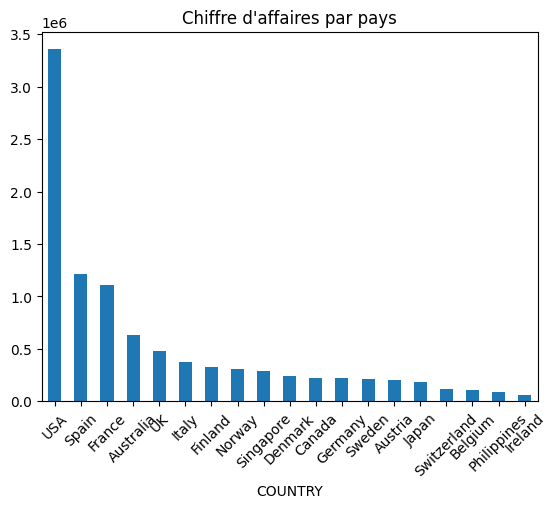

In [17]:
#Analyse par pays 
sales_by_country = df.groupby("COUNTRY")["SALES"].sum().sort_values(ascending=False)

sales_by_country.plot(kind="bar")
plt.title("Chiffre d'affaires par pays")
plt.xticks(rotation=45)
plt.show()

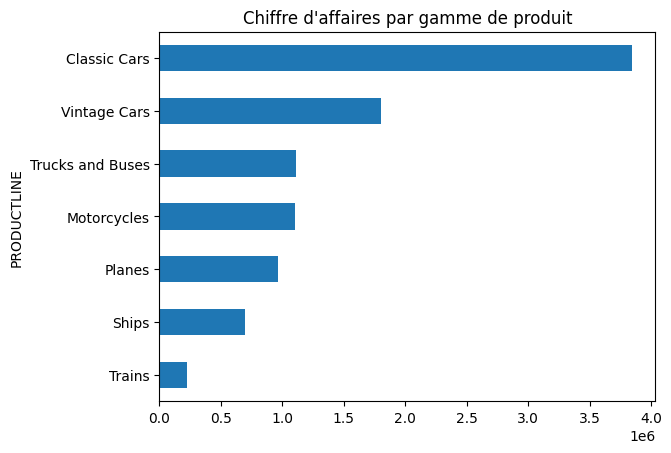

In [18]:
#Analyse par gamme de produit
sales_by_productline = df.groupby("PRODUCTLINE")["SALES"].sum().sort_values()

sales_by_productline.plot(kind="barh")
plt.title("Chiffre d'affaires par gamme de produit")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

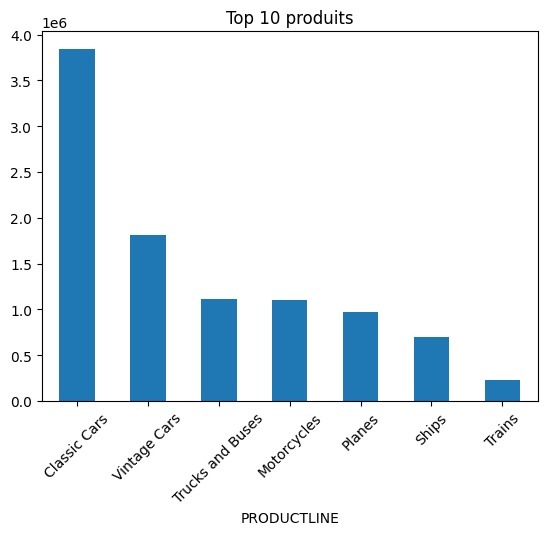

In [19]:
#Top 10 produits
top_products = df.groupby("PRODUCTLINE")["SALES"].sum().sort_values(ascending=False).head(10)

top_products.plot(kind="bar")
plt.title("Top 10 produits")
plt.xticks(rotation=45)
plt.show

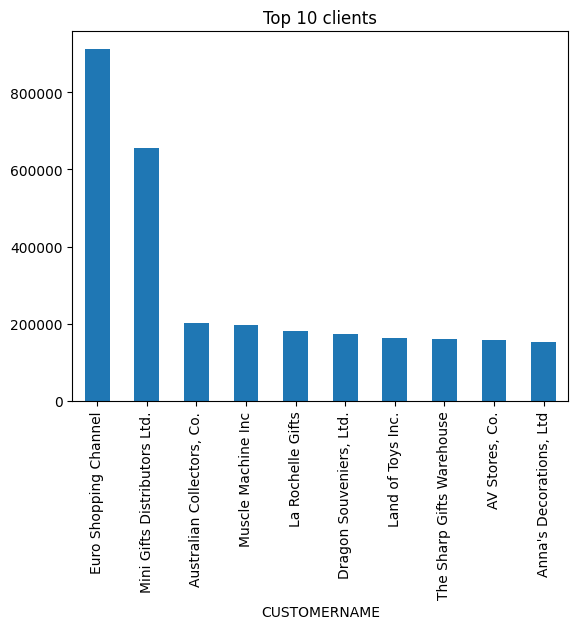

In [20]:
#Analyse par client
top_clients = df.groupby("CUSTOMERNAME")["SALES"].sum().sort_values(ascending=False).head(10)

top_clients.plot(kind="bar")
plt.title("Top 10 clients")
plt.show()



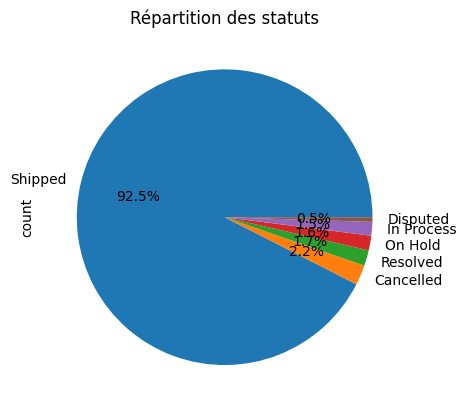

In [21]:
#Aanalyse des status 
status_counts = df["STATUS"].value_counts()

status_counts.plot(kind="pie",autopct='%1.1f%%')
plt.title("Répartition des statuts")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

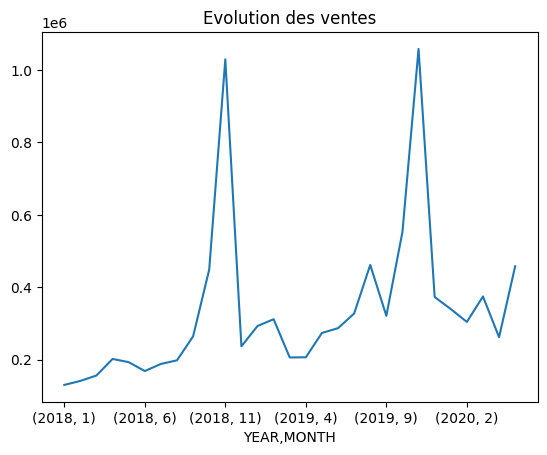

In [23]:
#Analyse temporelle

#Extraire mois et année
df["YEAR"] = df["ORDERDATE"].dt.year
df["MONTH"] = df["ORDERDATE"].dt.month

#Chiffre d'affaires par mois
monthly_sales = df.groupby(["YEAR","MONTH"])["SALES"].sum()

monthly_sales.plot()
plt.title("Evolution des ventes")
plt.show

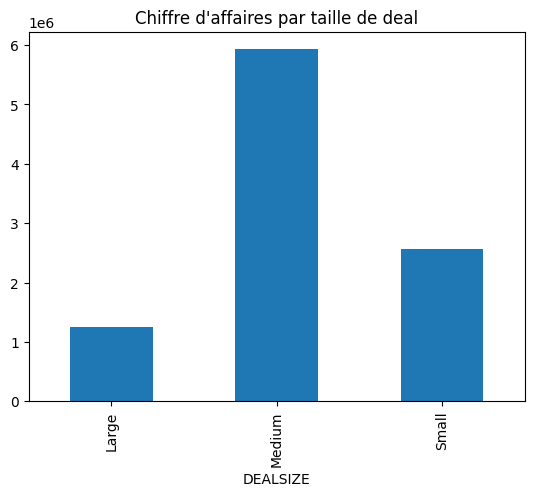

In [24]:
#Analyse par taille de deal
deal_sales = df.groupby("DEALSIZE")["SALES"].sum()

deal_sales.plot(kind="bar")
plt.title("Chiffre d'affaires par taille de deal")
plt.show()

In [25]:
#Création de la colonne panier moyen par commande
avg_order_value = df.groupby("ORDERNUMBER")["SALES"].sum().mean()
print("Panier moyen :",avg_order_value)

Panier moyen : 32752.421845637582
